# Recurring Tasks

**Question:** Can a learner accumulate three independent representations when only the active task's readout is useful?

Three fixed teachers each map 21 independent ±1 inputs through 10 LTUs to 10 linear outputs. Teacher weights are ±1 and every target has independent Gaussian noise of standard deviation 1. Every 10,000 examples, choose uniformly between the other two teachers. All tasks share input and output coordinates; no task ID is supplied.

The learner has **21 inputs → 30 LTUs → 10 linear outputs**, enough features to hold all teachers at once. Weights, optimizer state, and centering statistics persist across switches. All biases are weights on constant-1 inputs. Predictions are scored before learning each target.

Compare five SGD step sizes and network Autostep, using the same five seeds for every configuration. SGD uses fan-in initialization and sigmoid surrogate derivatives. Autostep uses **meta step 0.02, initial step 1e-5**, hidden weights uniform in ±1e-5, and uncompensated activation/derivative centering (rate 1e-3). Readouts start at zero. Autostep uses the `squared_inputs` implementation from the network Autostep notebooks, with normalization time constant 1e4.

**Privileged reference:** a shared linear Autostep readout of all 30 fixed, true teacher features, centered at 0.5. It receives neither the active task ID nor correct output weights. Only its readout learns, with the same Autostep settings and five seeds. This measures achievable readout adaptation with perfect features; it is not a proven optimal bound. Noise RMSE 1 is a lower bound, not the expected online optimum after unannounced switches.

Methods share teachers, switches, inputs and noise for matching seed IDs. The first plot shows every SGD rate. The second compares the SGD rate with the lowest mean per-seed RMSE over the final 100k examples against Autostep and the ideal-feature baseline, using the same runs without retraining.

In [1]:
from functools import partial
from pathlib import Path
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS = 3
N_HIDDEN = N_TASKS * WIDTH

# Autostep: uncompensated centering and small hidden initialization.
INIT_RATE, META_RATE, EMA_RATE = 1e-5, .02, 1e-3

# Training
PERIOD = 10_000
BLOCKS = 50
WINDOW = 1000
SGD_EXPONENTS = (-12, -10, -8, -6, -4)
SGD_RATES = [2.**p for p in SGD_EXPONENTS]
N_SEEDS = 5
assert PERIOD % WINDOW == 0

## Task

In [3]:
def init_teacher(key):
    input_key, _, output_key = jax.random.split(key, 3)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > 0).astype(jnp.float32)

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True,
                       tau=1e4, version='squared_inputs')

class Learner(NamedTuple):
    weights: tuple
    opt: object
    means: tuple
    slopes: tuple


def init_learner(key, widths, method):
    weights = []
    fan_in = N_INPUTS
    for width, subkey in zip(widths, jax.random.split(key, len(widths))):
        bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / fan_in)
        w = jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound)
        weights.append(w.at[:, -1].set(0.))
        fan_in = width
    weights.append(jnp.zeros((N_OUTPUTS, fan_in + 1)))
    weights = tuple(weights)
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   tuple(jnp.full(w.shape[0], .5) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]))


def forward(weights, x, learner, method):
    sources, means, slopes = [], [], []
    for w, mean, slope in zip(weights[:-1], learner.means, learner.slopes):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        x = ltu(z)
        if method == 'Autostep':
            # Same uncompensated centering and centered surrogate as network_autostep.
            mean = mean + EMA_RATE * (jax.lax.stop_gradient(x) - mean)
            sigmoid = jax.nn.sigmoid(z)
            derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))
            slope = slope + EMA_RATE * (derivative[:, None] * jax.lax.stop_gradient(source) - slope)
            correction = jnp.sum(slope * w, axis=1)
            x = x - mean + (jax.lax.stop_gradient(correction) - correction)
        means.append(mean)
        slopes.append(slope)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes))


def update(learner, x, y, method, rate):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, method)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, means, slopes)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -rate * g, grads), None
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, means, slopes), 2 * loss_value / N_OUTPUTS

## Training

In [5]:
def train(seed, rate, method, reference=False):
    teacher_key, learner_key, schedule_key, rng = jax.random.split(jax.random.PRNGKey(seed), 4)
    teachers = jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))
    if reference:
        weights = (jnp.zeros((N_OUTPUTS, N_HIDDEN + 1)),)
        learner = Learner(weights, OPTIMIZER.init(weights), (), ())
    else:
        learner = init_learner(learner_key, (N_HIDDEN,), method)

    def block(carry, block_id):
        learner, rng, task_id = carry
        offset = jax.random.randint(jax.random.fold_in(schedule_key, block_id), (), 1, N_TASKS)
        task_id = jnp.where(block_id == 0, task_id, (task_id + offset) % N_TASKS)
        teacher = jax.tree.map(lambda w: w[task_id], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            if reference:
                # All true features, with no indication of which task is active.
                x = (jnp.einsum('thi,i->th', teachers[0], x) > 0).astype(jnp.float32).reshape(-1) - .5
            learner, mse = update(learner, x, y, method, rate)
            return (learner, rng), mse

        def record(carry, _):
            carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
            return carry, mse.mean()
        (learner, rng), mse = jax.lax.scan(record, (learner, rng), length=PERIOD // WINDOW)
        return (learner, rng, task_id), mse

    task_id = jax.random.randint(schedule_key, (), 0, N_TASKS)
    _, mse = jax.lax.scan(block, (learner, rng, task_id), jnp.arange(BLOCKS))
    return mse


@partial(jax.jit, static_argnames=('method', 'reference'))
def train_many(seeds, rates, method, reference=False):
    one = partial(train, method=method, reference=reference)
    # Inner vmap: seeds; outer vmap: step sizes.
    return jax.vmap(jax.vmap(one, in_axes=(0, None)), in_axes=(None, 0))(seeds, rates)


def run(method, rates=None, reference=False):
    started = perf_counter()
    rates = jnp.asarray([INIT_RATE] if rates is None else rates, dtype=jnp.float32)
    mse = np.asarray(train_many(jnp.arange(N_SEEDS), rates, method, reference))
    assert np.isfinite(mse).all()
    print(f'{method}{" ideal features" if reference else ""}: {perf_counter() - started:.1f}s including compilation')
    return mse

In [6]:
started = perf_counter()
sgd = run('SGD', rates=SGD_RATES)
autostep = run('Autostep')
reference = run('Autostep', reference=True)
seconds = perf_counter() - started
np.savez_compressed(RESULTS / 'recurring_tasks.npz', sgd=sgd, autostep=autostep,
                    reference=reference, rates=SGD_RATES, period=PERIOD,
                    window=WINDOW, seconds=seconds)
print(f'Complete comparison: {seconds:.1f}s including compilation.')
assert seconds < 120, 'Simplify the experiment before extending it.'

SGD: 8.6s including compilation
Autostep: 11.5s including compilation
Autostep ideal features: 7.8s including compilation
Complete comparison: 27.9s including compilation.


## Plots

SGD $2^{-12}$: last 10 blocks 1.6910; preceding 10 1.6876
SGD $2^{-10}$: last 10 blocks 1.4593; preceding 10 1.4672
SGD $2^{-8}$: last 10 blocks 1.2161; preceding 10 1.2350
SGD $2^{-6}$: last 10 blocks 1.1345; preceding 10 1.1407
SGD $2^{-4}$: last 10 blocks 1.6400; preceding 10 1.6394
Autostep: last 10 blocks 1.1507; preceding 10 1.2011
Ideal-feature baseline: last 10 blocks 1.0772; preceding 10 1.0769
Comparison uses SGD 2^(-6), chosen by final-100k RMSE from the plotted sweep.


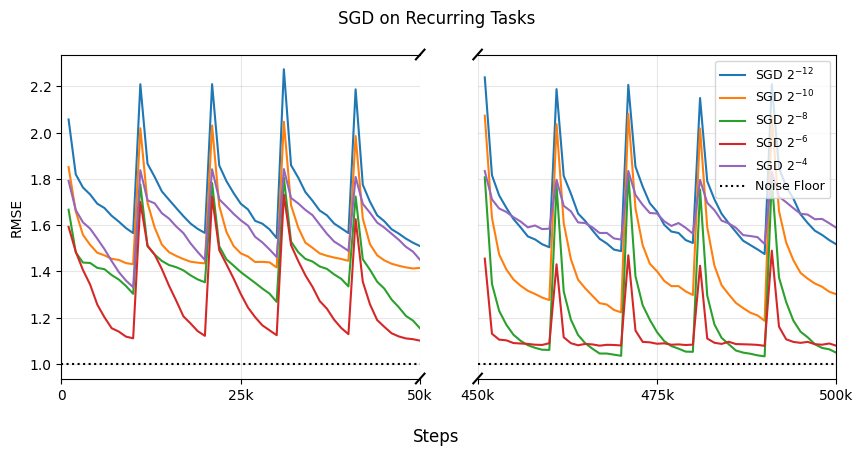

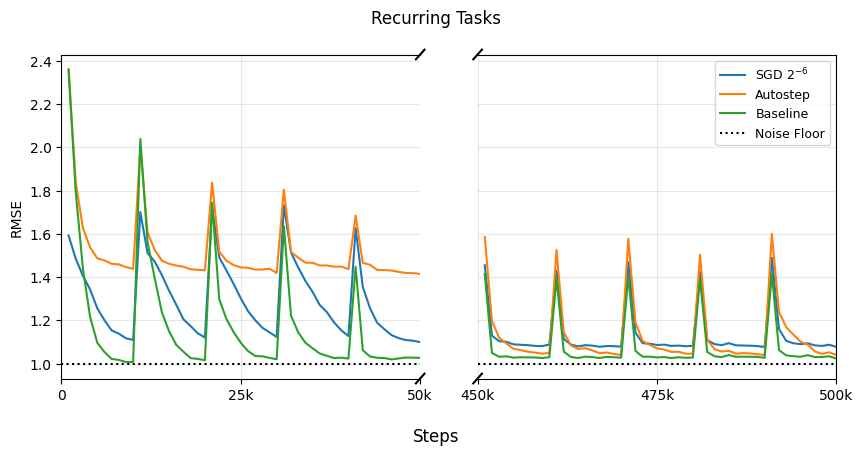

In [7]:
x = np.arange(1, BLOCKS * PERIOD // WINDOW + 1) * WINDOW
sgd_labels = [rf'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS]
late_scores = np.sqrt(sgd[:, :, -10:].mean(axis=(2, 3))).mean(axis=1)
best = int(np.argmin(late_scores))


def plot_broken_time(curves, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True,
                             gridspec_kw={'wspace': .16})
    for ax, (left, right) in zip(axes, ((0, 50_000), (450_000, 500_000))):
        visible = (x > left) & (x <= right)
        for label, values in curves:
            values = values.reshape(len(values), -1)
            ax.plot(x[visible], np.sqrt(values[:, visible]).mean(axis=0), label=label)
        ax.axhline(1., color='black', ls=':', label='Noise Floor')
        ax.set_xlim(left, right)
        ticks = np.linspace(left, right, 3)
        ax.set_xticks(ticks, ['0' if t == 0 else f'{t / 1000:g}k' for t in ticks])
        ax.grid(True, alpha=.3)
    axes[0].spines['right'].set_visible(False)
    axes[1].spines['left'].set_visible(False)
    axes[1].tick_params(axis='y', left=False)
    # Diagonal bars mark the omitted middle interval; the two time spans are equal.
    for ax, side in ((axes[0], 1), (axes[1], 0)):
        for height in (0, 1):
            ax.plot((side-.012, side+.012), (height-.015, height+.015),
                    transform=ax.transAxes, color='black', clip_on=False, lw=1.5)
    axes[0].set_ylabel('RMSE')
    axes[1].legend(fontsize=9)
    fig.suptitle(title)
    fig.supxlabel('Steps')
    fig.subplots_adjust(bottom=.16, top=.88)
    plt.show()


plot_broken_time(list(zip(sgd_labels, sgd)), 'SGD on Recurring Tasks')
plot_broken_time([(sgd_labels[best], sgd[best]),
                  ('Autostep', autostep[0]),
                  ('Baseline', reference[0])],
                 'Recurring Tasks')
for label, values in list(zip(sgd_labels, sgd)) + [('Autostep', autostep[0]), ('Ideal-feature baseline', reference[0])]:
    late = np.sqrt(values[:, -10:].mean(axis=(1, 2)))
    previous = np.sqrt(values[:, -20:-10].mean(axis=(1, 2)))
    print(f'{label}: last 10 blocks {late.mean():.4f}; preceding 10 {previous.mean():.4f}')
print(f'Comparison uses SGD 2^({SGD_EXPONENTS[best]}), chosen by final-100k RMSE from the plotted sweep.')

All curves use five paired seeds; no uncertainty bands are shown. Both plots display only 0–50k and 450–500k examples, with diagonal bars marking the time break. Late-window scores include all switch costs; a late score alone does not establish steady state.

**Result (27.9s on GPU):** Final-100k RMSE is 1.691, 1.459, 1.216, 1.135, and 1.640 across ascending SGD rates. The comparison therefore shows SGD at $2^{-6}$ (1.135), Autostep (1.151), and the ideal-feature baseline (1.077). Autostep improved from 1.201 in the preceding 100k examples; this is not an established steady-state gap.
